<a href="https://colab.research.google.com/github/20danaai/Learn_LibrariesPy/blob/main/01_WorckFlow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt


Build some data using linear regression simple equation
y = weight * x + bias

In [2]:
weight=0.7
bias=0.3

In [3]:
x=torch.arange(0,1,0.02)
x.shape


torch.Size([50])

In [4]:
y=weight*x+bias
y.shape

torch.Size([50])

In [5]:
x[:5],y[:5]

(tensor([0.0000, 0.0200, 0.0400, 0.0600, 0.0800]),
 tensor([0.3000, 0.3140, 0.3280, 0.3420, 0.3560]))

In [6]:
train_split=int(0.8*len(x))
train_x,test_x=x[:train_split],x[train_split:]
train_y,test_y=y[:train_split],y[train_split:]

In [7]:
len(train_x),len(test_x)

(40, 10)

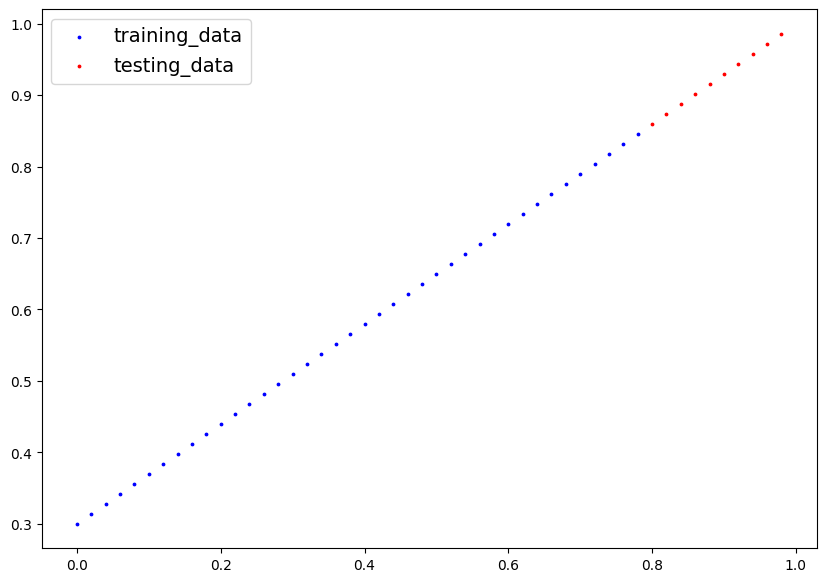

In [8]:
def plot_predictions(train_data=train_x,
                     train_lable=train_y, # correct classifications for training data
                     test_data=test_x,
                     test_lable=test_y,
                     predictions=None):
  plt.figure(figsize=(10,7)) # creates a new drawing space
  plt.scatter(train_data,train_lable,c='b',s=3,label='training_data') # plot points on the chart , label (group name in the legend)
  plt.scatter(test_data,test_lable,c='r',s=3,label='testing_data')
  if predictions is not None:
       plt.scatter(test_data,predictions,c='g',s=3,label='predictions')
  plt.legend(prop={'size':14}) # a small box appears , containing the names of the groups
plot_predictions()



Lets build the model

In [9]:
class LinearRegressionsModule(nn.Module):
  def __init__(self):
     super().__init__()
     self.weight=nn.Parameter(torch.rand(1,dtype=torch.float),requires_grad=True) #erro : capital P Prameters
     self.bias=nn.Parameter(torch.rand(1,dtype=torch.float),requires_grad=True)
  def forward(self,x:torch.tensor)-> torch.tensor: # what the model will do
          return self.weight*x+self.bias

In [10]:
torch.manual_seed(42) # for fixing rand num of the start value
model_0= LinearRegressionsModule() # create model instance
list(model_0.parameters())

[Parameter containing:
 tensor([0.8823], requires_grad=True),
 Parameter containing:
 tensor([0.9150], requires_grad=True)]

In [11]:
model_0.state_dict()

OrderedDict([('weight', tensor([0.8823])), ('bias', tensor([0.9150]))])

In [12]:
with torch.inference_mode(): # for pred
  y_pred=model_0(test_x)

In [13]:
print(y_pred.shape),print(test_x.shape),print(y_pred.shape)

torch.Size([10])
torch.Size([10])
torch.Size([10])


(None, None, None)

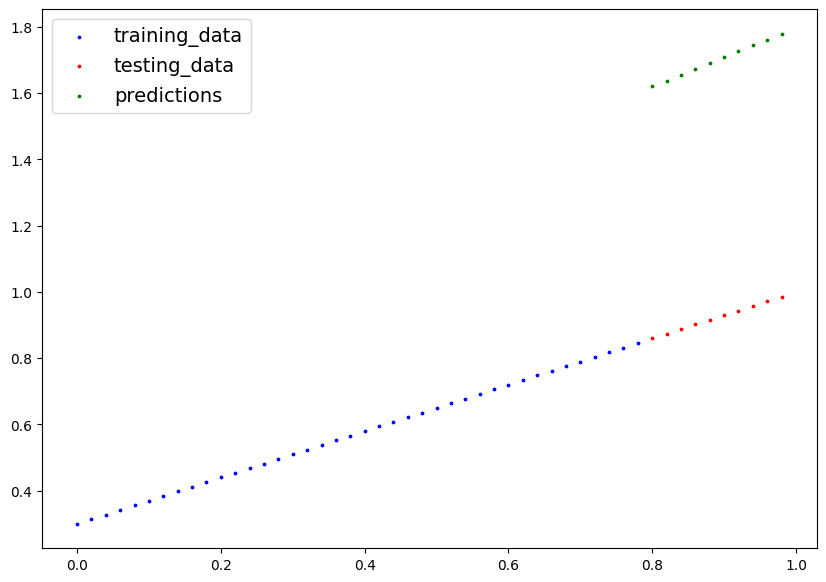

In [14]:
plot_predictions(predictions=y_pred)

In [15]:
loss_n=nn.L1Loss() # MAE loss fun for our model , dif = y_red[0]-test_y[0]

In [16]:
optimizer=torch.optim.SGD(params=model_0.parameters(),lr=0.01)

In [17]:
torch.manual_seed(42)
epochs=100
train_loss_values=[]
test_loss_values=[]
epochs_count=[]
for epoch in range(epochs):
  model_0.train()
  y_pred=model_0(train_x)
  loss=loss_n(y_pred,train_y)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model_0.eval()
  with torch.inference_mode():
      test_pred=model_0(test_x)
      test_loss=loss_n(test_pred,test_y)
  if epoch % 10==0:
      epochs_count.append(epoch)
      train_loss_values.append(loss.detach().numpy())
      test_loss_values.append(test_loss.detach().numpy())
      print(f'Epoch:{epoch} | MAE Train loss :{loss} | MAE Testing loss : {test_loss}')

Epoch:0 | MAE Train loss :0.6860889196395874 | MAE Testing loss : 0.7637526988983154
Epoch:10 | MAE Train loss :0.5708791017532349 | MAE Testing loss : 0.6290428042411804
Epoch:20 | MAE Train loss :0.45566922426223755 | MAE Testing loss : 0.4943329691886902
Epoch:30 | MAE Train loss :0.34045934677124023 | MAE Testing loss : 0.35962313413619995
Epoch:40 | MAE Train loss :0.2252494841814041 | MAE Testing loss : 0.2249133139848709
Epoch:50 | MAE Train loss :0.1100396141409874 | MAE Testing loss : 0.09020347893238068
Epoch:60 | MAE Train loss :0.009724985808134079 | MAE Testing loss : 0.020998019725084305
Epoch:70 | MAE Train loss :0.006216754671186209 | MAE Testing loss : 0.014099234715104103
Epoch:80 | MAE Train loss :0.002788322512060404 | MAE Testing loss : 0.005826681852340698
Epoch:90 | MAE Train loss :0.007095950655639172 | MAE Testing loss : 0.00754010071977973


10
10
10


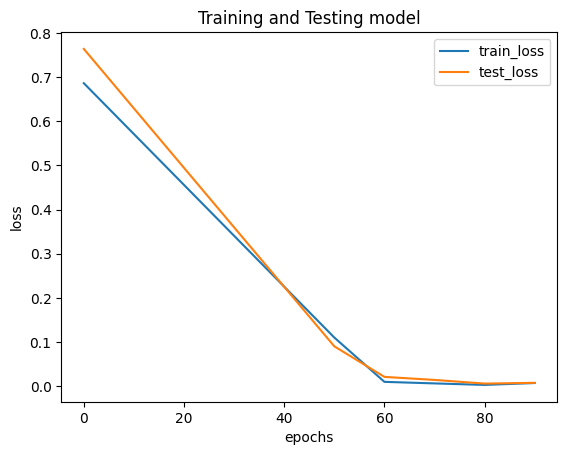

In [18]:
plt.plot(epochs_count,train_loss_values,label='train_loss')
plt.plot(epochs_count,test_loss_values,label='test_loss')
plt.title('Training and Testing model')
plt.xlabel('epochs')
plt.ylabel('loss')
plt.legend()
print(len(epochs_count))
print(len(train_loss_values))
print(len(test_loss_values))

In [20]:
model_0.state_dict()

OrderedDict([('weight', tensor([0.6977])), ('bias', tensor([0.3080]))])

In [21]:
model_0.eval()
with torch.inference_mode():
  y_pred_train=model_0(test_x)


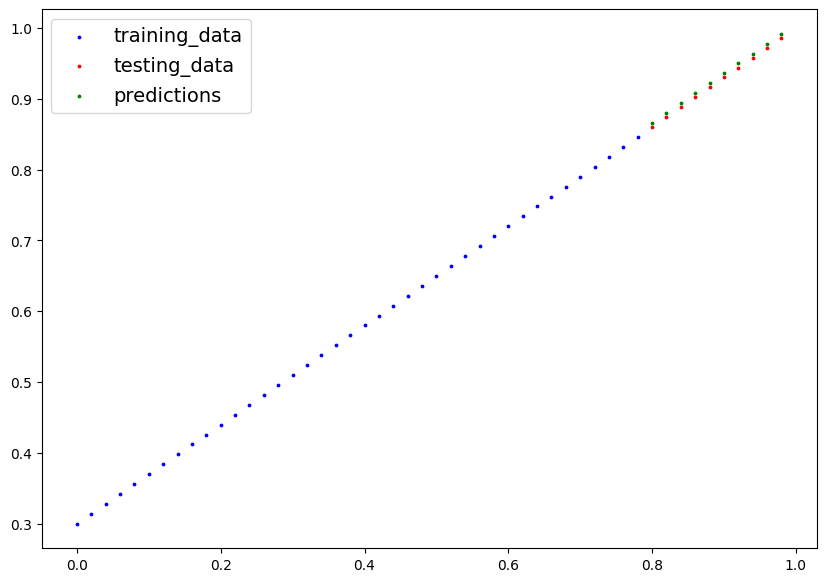

In [23]:
plot_predictions(predictions=y_pred_train)

how to save and load a pytorch model ?
 1:torch.save  2:torch.load

In [24]:
torch.save(model_0,'./model.pth')

In [25]:
torch.save(model_0,'./model.pt')

In [27]:
from pathlib import Path
# create a directory
model_path=Path('models')
model_path.mkdir(parents=True,exist_ok=True)
# create model save path
model_name='01_workflow_model.pth'
model_save=model_path/model_name

In [28]:
torch.save(model_0.state_dict(),model_save)



In [31]:
# torch.nn.Module.load_state_dict
# instance of our model
torch.manual_seed(42)
model_1=LinearRegressionsModule()
model_1.state_dict()
model_1.load_state_dict(torch.load(model_save))
model_1.state_dict()

OrderedDict([('weight', tensor([0.6977])), ('bias', tensor([0.3080]))])

In [32]:
model_1.eval()
with torch.inference_mode():
  y_pred2=model_1(test_x)
y_pred_train==y_pred2

tensor([True, True, True, True, True, True, True, True, True, True])